<a href="https://colab.research.google.com/github/Prktriesitout/LangGraph/blob/main/Project1Langgraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Business Scenario:

A customer support bot must handle incoming messages and decide whether to answer FAQs, escalate to an agent, or log complaints.

 Problem Statement:

Design a StateGraph that:

Starts with a classify_query node to categorize user message.
Based on classification:
Goes to faq_node if question is informational.
Goes to escalate_node if it’s complex.
Goes to complaint_node if user is dissatisfied.
 Steps to Follow:

Define State schema with keys: query, type, response.
Build a graph with nodes for classification and handling.
Use conditional edges based on type.
Compile and run the graph with a few queries

In [1]:
!pip install -q langgraph

stategraph -> graphbuilder  ,
start, end -> Special markers for the entry and exit points
TypedDIct -> Defines the State schema with the keys query, type and response

In [2]:
from langgraph.graph import StateGraph , START, END
from typing import TypedDict
print("LangGraph is ready")

LangGraph is ready


In [3]:
!pip install -q langchain-openai

In [4]:
from typing import TypedDict
class State(TypedDict):
  query: str
  type: str
  response: str

In [5]:
def classify_query(state: State) -> dict:   # sets only the type
  q = state["query"].lower()

  complaint_words = ["delayed", "late", "again", "worst", "terrible", "dissapointed", "damaged", "not happy", "bad service"]
  esclate_words = ["refund","cancel","charged twice","payment failed","account locked","human","agent","legal"]

  if any(w in q for w in complaint_words):
    return {"type": "complaint"}
  elif any(w in q for w in esclate_words):
    return {"type": "escalate"}
  else:
    return {"type": "faq"}

def faq_node(state: State) -> dict :
  return {"response": "Here's the information you asked for. Check our FAQ page for more details."}

def escalate_node(state: State) -> dict:
  return {"response": "This needs special attention. I'm connecting you to a human agent." }

def complaint_node(state: State) -> dict:
  return {"response": "Sorry about that. I've logged your complaint and will work on it."}

In [6]:
for q in ["My order id delayed again!","I want a refund", "What are your working hours?"]:
  print(q, classify_query({"query": q, "type": "", "response": ""}))

My order id delayed again! {'type': 'complaint'}
I want a refund {'type': 'escalate'}
What are your working hours? {'type': 'faq'}


In [7]:
def route_query(state: State) -> dict:
  if state["type"] == "faq":
    return faq_node(state)
  elif state["type"] == "escalate":
    return escalate_node(state)
  else:
    return complaint_node(state)

In [8]:
from langgraph.graph import StateGraph , START, END

builder = StateGraph(State)

builder.add_node(classify_query, name="classify_query")
builder.add_node(faq_node, name="faq_node")
builder.add_node(escalate_node, name="escalate_node")
builder.add_node(complaint_node, name="complaint_node")

builder.add_edge(START, "classify_query")

builder.add_conditional_edges(
    "classify_query",
    route_query,
    {
        "faq_node": "faq_node",
        "escalate_node": "escalate_node",
        "complaint_node": "complaint_node",
    }
)

builder.add_edge("faq_node", END)
builder.add_edge("escalate_node", END)
builder.add_edge("complaint_node", END)




In [11]:
graph = builder.compile()

for q in ["My order is delayed again!", "I want a refund for my purchase", "What are your working hours?"]:
    result = graph.invoke({"query": q, "type": "", "response": ""})
    print(f"Query:    {q}")
    print(f"Type:     {result['type']}")
    print(f"Response: {result['response']}")
    print("-" * 50)

Query:    My order is delayed again!
Type:     complaint
Response: Sorry about that. I've logged your complaint.
--------------------------------------------------
Query:    I want a refund for my purchase
Type:     escalate
Response: This needs special attention. I'm connecting you to a human agent.
--------------------------------------------------
Query:    What are your working hours?
Type:     faq
Response: Here's the information you asked for. Check our FAQ page for more details.
--------------------------------------------------


In [15]:
def run_with_path(query: str):
    path = []
    final = {}
    for step in graph.stream({"query": query, "type": "", "response": ""}):
        node_name = list(step.keys())[0]
        path.append(node_name)
        final.update(step[node_name])
    print(f"Input:    {query}")
    print(f"Path:     {' → '.join(path)}")
    print(f"Response: {final['response']}")
    print("-" * 60)

run_with_path("My order is delayed again!")

Input:    My order is delayed again!
Path:     classify_query → complaint_node
Response: Sorry about that. I've logged your complaint.
------------------------------------------------------------


In [16]:
for q in [
    "My order is delayed again!",
    "I want a refund for my purchase",
    "What are your working hours?",
    "Where can I track my order?",
    "This is the worst service ever",
    "Please connect me to an agent",
]:
    run_with_path(q)

Input:    My order is delayed again!
Path:     classify_query → complaint_node
Response: Sorry about that. I've logged your complaint.
------------------------------------------------------------
Input:    I want a refund for my purchase
Path:     classify_query → escalate_node
Response: This needs special attention. I'm connecting you to a human agent.
------------------------------------------------------------
Input:    What are your working hours?
Path:     classify_query → faq_node
Response: Here's the information you asked for. Check our FAQ page for more details.
------------------------------------------------------------
Input:    Where can I track my order?
Path:     classify_query → faq_node
Response: Here's the information you asked for. Check our FAQ page for more details.
------------------------------------------------------------
Input:    This is the worst service ever
Path:     classify_query → complaint_node
Response: Sorry about that. I've logged your complaint.
---

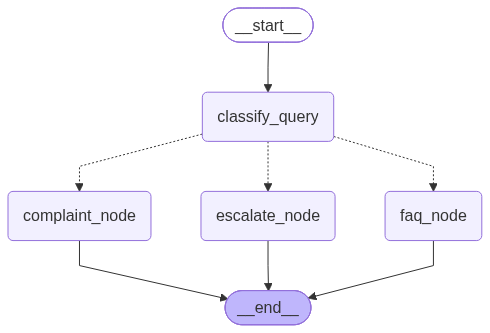

In [17]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))